In [99]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import ast
from adjustText import adjust_text

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x : ast.literal_eval(x) if pd.notna(x) else x)

ModuleNotFoundError: No module named 'adjustText'

In [ ]:
df = df[df['job_title_short'] == 'Data Analyst']

In [ ]:
df_exploded = df.explode('job_skills')
skill_stats = df_exploded.groupby('job_skills').agg(
    skill_count = ('job_skills', 'count'),
    median_salary = ('salary_year_avg', 'median')
)

skill_stats

,skill_count,median_salary
job_skills,,
airflow,2002,111175.0
airtable,88,90000.0
alteryx,4570,105000.0
angular,376,109101.0
angular.js,2,NaN
...,...,...
wrike,39,75000.0
wsl,16,NaN
xamarin,2,NaN


In [ ]:
skill_stats = skill_stats.sort_values(by = 'skill_count', ascending=False).head(20)

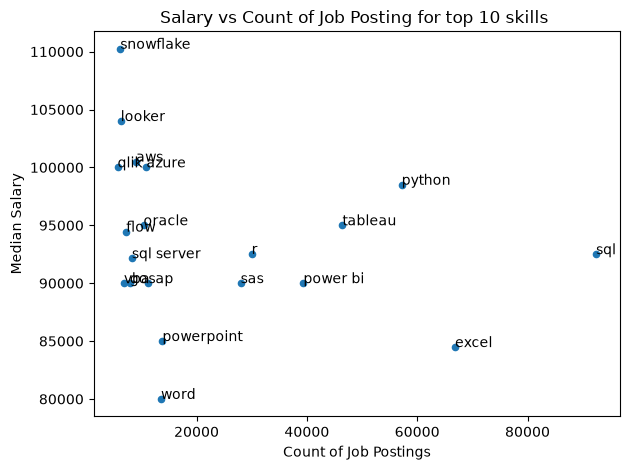

In [ ]:
skill_stats.plot(kind='scatter', x='skill_count', y='median_salary')
plt.xlabel('Count of Job Postings')
plt.ylabel('Median Salary')
plt.title('Salary vs Count of Job Posting for top 10 skills ')
plt.tight_layout()
for i,txt in enumerate(skill_stats.index):
    plt.text(skill_stats['skill_count'].iloc[i], skill_stats['median_salary'].iloc[i], txt)

plt.show()

In [ ]:
df_DA_ind = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'India')] .copy()
#df_DA_ind = df_DA_ind.dropna(subset = ['salary_year_avg'])

Text(0.5, 0, 'Yearly Salary')

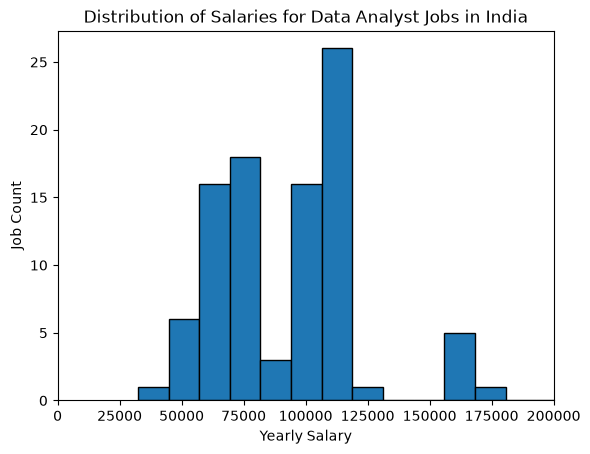

In [ ]:
df_DA_ind['salary_year_avg'].plot(kind='hist', bins=50, edgecolor='black')
plt.xlim(0,200000)
plt.title('Distribution of Salaries for Data Analyst Jobs in India')
plt.ylabel('Job Count')
plt.xlabel('Yearly Salary')
#ax = plt.gca()
#ax.xaxis.set_major_formatter(plt.Func_Formatter(lambda x, _: f'${int(x/100)}K'))

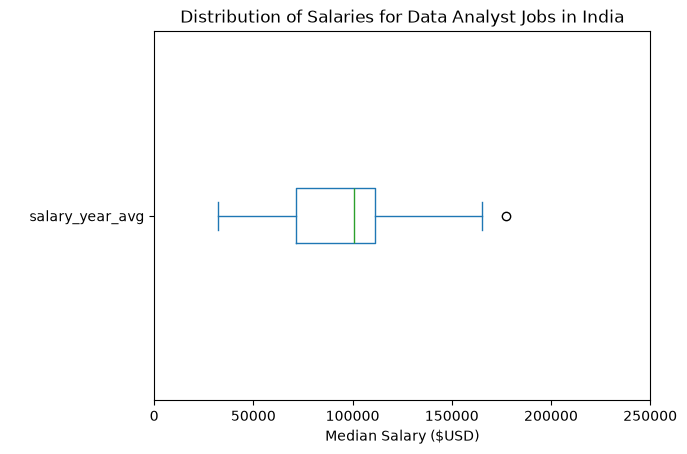

In [ ]:
df_DA_ind['salary_year_avg'].plot(kind='box', vert=False)
plt.xlim(0,250000)
plt.title('Distribution of Salaries for Data Analyst Jobs in India')
plt.ylabel(' ')
plt.xlabel('Median Salary ($USD)')
plt.show()

C:\Users\prajw\AppData\Local\Temp\ipykernel_24396\3872397549.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(job_list, tick_labels=job_titles, vert=False)


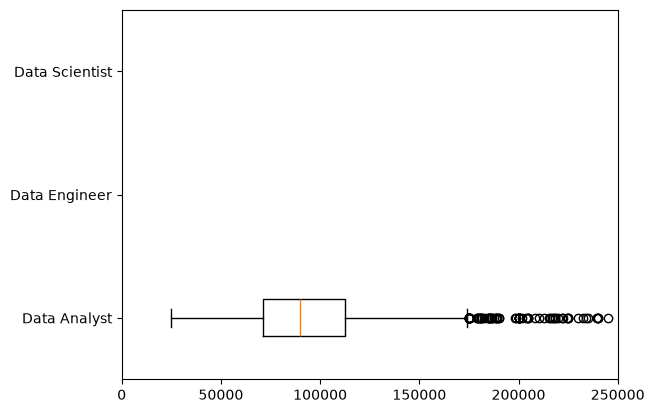

In [100]:
job_titles = ['Data Analyst', 'Data Engineer', 'Data Scientist']

df_ind = df[
    (df['job_title_short'].isin(job_titles)) &
    (df['job_country'] == 'United States')
].copy()

df_ind = df_ind.dropna(subset=['salary_year_avg'])

job_list = [
    df_ind[df_ind['job_title_short'] == job_title]['salary_year_avg']
    for job_title in job_titles
]

plt.boxplot(job_list, tick_labels=job_titles, vert=False)
plt.xlim(0, 250000)
plt.show()

In [101]:
df_ind['job_title_short'].value_counts()

job_title_short
Data Analyst    4350
Name: count, dtype: int64

In [102]:
for job_title in job_titles:
    print(job_title, len(df_ind[df_ind['job_title_short'] == job_title]))

Data Analyst 4350
Data Engineer 0
Data Scientist 0
